# Grid Day Types and a Learning Battery

**Three kinds of machine learning on one real electricity grid.** Using two years of hourly demand from Colorado's grid (Public Service Company of Colorado, PSCO), this notebook asks two questions nobody has labeled data for:

1. *What kinds of days does this grid actually have?* (unsupervised learning: clustering)
2. *Could a battery learn when to charge and when to give energy back, without anyone writing it a schedule?* (reinforcement learning)

Between the two sits a supervised classifier that guesses tomorrow's kind of day at midnight, so the battery agent only uses information it would really have.

Every score is shown beside the score of a plan that learned nothing (its **floor**). A result that doesn't beat its floor isn't a result.

### Results summary

| Stage | Result | Floor beside it |
|---|---|---|
| Day types (k-means, k = 2) | silhouette 0.4951; identical grouping across 10 random seeds (ARI 1.0) | 0.3986 on random data with no clusters |
| Midnight classifier (logistic regression) | 90.30% accuracy on 2025 | 68.70% always guessing the common type |
| Battery agent (Q-learning, predicted day types) | 83.07% of the best possible schedule on 2025 | 0% doing nothing; 80.48% a fixed clock rule; 83.29% a rule fitted to 2024 |

**Takeaway:** the grid has two clear kinds of day, and they are predictable the night before. A learned battery agent captures about 83% of the value a perfect-foresight schedule could, but a simple rule fitted to the 2024 average day does just as well, so the learning only pays off if it is worth its extra complexity. (In the appendix I tried two alternative clustering methods, drawing the day-type boundaries with Ward clustering instead raised the agent to 86.00%.)

*Numbers below come from the runs shown. EIA occasionally revises past data, so a fresh run can differ slightly in the last digits.*

## 1. Background, data, and limits

### Motivation

A city is weighing a battery at its connection to the power grid. The busiest hours of the day are the most expensive to serve, and a battery that stores energy in the quiet hours and gives it back in the busy ones is how a city pays less for its peaks. Two things are not available to look up: what kinds of days the grid actually has (grid operators publish demand hour by hour and nothing else, so no day has ever been labeled), and whether a battery could learn its own charging schedule. It also cannot see tomorrow, so whatever it learns has to work from what is known at midnight.

### Region and question

I chose the Public Service Company of Colorado (PSCO) because I am interested in training a model on data from my own local area, where demand patterns are not trivially simple to classify without clustering. This notebook investigates what distinct daily load shapes characterize this power grid and determines whether a reinforcement learning battery agent can learn a good charging schedule entirely from experience, without a hardcoded rule.

### Data source and terms

The data is published by the **U.S. Energy Information Administration (EIA)** and is collected on **Form EIA-930** (Hourly Real-Time Demand with Balancing Authority Liaison). According to the EIA's Copyrights and Reuse page: "Information produced by Federal agencies and containing no copyrighted material is in the public domain and may be reproduced or used without permission." Source: U.S. Energy Information Administration.

### What this data leaves out

* The data is hourly electricity demand aggregated at the level of regional balancing authorities (such as PSCO). It does not capture local distribution outages, sub-transmission constraints, or behind-the-meter solar generation that reduces net demand directly.
* It covers exactly two years (2024 and 2025), so it excludes long-term multi-decade weather trends, extreme historical climate anomalies, and future shifts in electric vehicle adoption.

### Conventions

Everything is learned on **2024**. **2025** stays unseen until the classifier and the battery agent are tested on it. Hours are numbered 1 to 24 the way EIA reports them: hour *h* is the hour ending at *h*:00, so hour 19 is 6 to 7 PM.

## 2. Setup

Library versions, the data loader, the clustering helpers, and the battery environment.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import adjusted_rand_score, confusion_matrix, silhouette_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("scikit-learn", sklearn.__version__)

# On some machines numpy reports harmless overflow warnings from inside scikit-learn's
# arithmetic; this turns the reports off so the tables stay readable. Results are identical.
np.seterr(over="ignore", invalid="ignore", divide="ignore")
print("numpy overflow reports: off for this notebook")

numpy        2.4.6
pandas       2.2.3
scikit-learn 1.6.1
numpy overflow reports: off for this notebook


### Loading the grid data

The loader reads EIA's published six-month files for the four regions in the study (ERCO, DUK, PJM, PSCO), keeps hourly adjusted demand, and caches the result locally. The first run downloads about 45 MB per file and takes a few minutes; later runs read the cache.

In [2]:
import os

CACHE = "eia930_demand_2024_2025.csv.gz"
EIA_FILE = "https://www.eia.gov/electricity/gridmonitor/sixMonthFiles/EIA930_BALANCE_{}.csv"
HALVES = ["2024_Jan_Jun", "2024_Jul_Dec", "2025_Jan_Jun", "2025_Jul_Dec"]
REGIONS = ["ERCO", "DUK", "PJM", "PSCO"]
EIA_COLUMNS = {"Balancing Authority": "ba", "Data Date": "date", "Hour Number": "hour",
               "Demand (MW) (Adjusted)": "demand_mw"}


def read_eia(file_pattern=EIA_FILE):
    """The four regions' hourly demand, read straight from EIA's six-month files."""
    parts = []
    for half in HALVES:
        part = pd.read_csv(file_pattern.format(half), usecols=list(EIA_COLUMNS),
                           thousands=",", low_memory=False).rename(columns=EIA_COLUMNS)
        parts.append(part[part["ba"].isin(REGIONS)])
        print("read", half)
    eia = pd.concat(parts, ignore_index=True)
    eia["date"] = pd.to_datetime(eia["date"], format="%m/%d/%Y")
    return eia.sort_values(["ba", "date", "hour"]).reset_index(drop=True)


def get_grid():
    """The cached copy if there is one; otherwise EIA's own files (then cache them)."""
    if os.path.exists(CACHE):
        print("using the cached copy:", CACHE)
        return pd.read_csv(CACHE, parse_dates=["date"])
    grid = read_eia()
    grid.to_csv(CACHE, index=False)
    return grid


grid = get_grid()
print("rows and columns:", grid.shape)

read 2024_Jan_Jun
read 2024_Jul_Dec
read 2025_Jan_Jun
read 2025_Jul_Dec
rows and columns: (70176, 4)


### Helpers

* `day_matrix` turns one region's long table (one row per hour) into the table to cluster (one row per day, one column per hour), dropping days that are not 24 hours long (the daylight-saving changeover days).
* `silhouette_control` builds a **no-cluster baseline**: random days with the real days' average and spread but no clusters in them, so I can see what silhouette score k-means gets on data with no groups at all. A real result has to beat it at the same k.
* `confusion_table` prints a labeled confusion matrix.

In [3]:
def day_matrix(grid, region):
    """One row per day, one column per hour, for one region.

    In: the whole grid table and a region code such as "ERCO". Out: a table of hourly
    demand in megawatts (rows are dates, columns are hours 1 to 24), and a dictionary
    saying how many days were dropped and why. A day is dropped when it is not 24 hours
    long (the two daylight-saving changeover days each year) or is missing an hour."""
    rows = grid[grid["ba"] == region]
    hours_per_day = rows.groupby("date")["hour"].count()
    full_days = hours_per_day[hours_per_day == 24].index
    days = rows[rows["date"].isin(full_days)].pivot(index="date", columns="hour",
                                                     values="demand_mw")
    missing_hour = int(days.isna().any(axis=1).sum())
    days = days.dropna().astype(float)
    report = {"days in the file": int(hours_per_day.size),
              "dropped, not 24 hours long": int((hours_per_day != 24).sum()),
              "dropped, missing an hour": missing_hour,
              "days kept": len(days)}
    return days, report


def silhouette_control(X, k_values, draws=5):
    """The no-cluster baseline for each k.

    In: your day matrix X (one row per day) and the k values to try. It draws `draws` sets
    of len(X) random days from one bell-shaped hump with X's average and spread (no
    clusters by construction), runs k-means on each, and scores it. Out: a table with the
    average and the highest of those silhouette scores for each k."""
    mu, cov = X.mean(axis=0), np.cov(X.T)
    scores = {k: [] for k in k_values}
    for seed in range(draws):
        S = np.random.default_rng(seed).multivariate_normal(mu, cov, size=len(X))
        for k in k_values:
            labels = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(S)
            scores[k].append(silhouette_score(S, labels))
    return pd.DataFrame({"k": list(k_values),
                         "control average": [np.mean(scores[k]) for k in k_values],
                         "control highest": [np.max(scores[k]) for k in k_values]})


def confusion_table(y_true, y_pred, names):
    """The confusion matrix as a labeled table: rows are the truth, columns the prediction.
    In: true types, predicted types, and a list of names in type-number order."""
    m = confusion_matrix(y_true, y_pred, labels=list(range(len(names))))
    table = pd.DataFrame(m, index=[f"true {n}" for n in names],
                         columns=[f"pred {n}" for n in names])
    print(table.to_string())
    return table

### The battery environment

A small world for the reinforcement-learning agent: a battery on the region's grid that can charge, hold, or discharge one unit each hour.

* **State:** the current hour (0 to 23) and the battery's charge (0 to 4 units). Later, the day type is added.
* **Actions:** 0 discharge (give one unit back), 1 hold, 2 charge (store one unit).
* **Reward:** charging costs that hour's *relative load* (the hour's demand divided by the day's average, so 1.30 means 30% busier than average). Discharging earns the relative load back at 90%, because a real battery loses energy on the way in and out. Holding, charging a full battery, or discharging an empty one earns 0.
* **Episode:** one day of 24 hourly steps, starting at midnight with an empty battery. Doing nothing all day therefore scores exactly 0, and any score above 0 is value the battery added.

Helpers score a policy (`run_policy`), provide two simple rules to beat (`clock_rule` and `make_fitted_rule`), compute the **oracle** (the best total any schedule could earn on a day if it knew the whole day in advance, so no agent can beat it), report a score as a share of the oracle (`share_of_oracle`), and read a trained agent's plan out of its Q-table (`show_policy`).

In [4]:
# The battery environment and the tools that score a policy.
#
# Hours inside the environment count from 0, the way Python counts: hour 0 is the hour
# from midnight to 1 AM (EIA's "hour 1"), and hour 23 is the hour from 11 PM to midnight.

DISCHARGE, HOLD, CHARGE = 0, 1, 2      # the three actions, numbered for the Q-table


class BatteryEnv:
    """A battery on your region's grid. One episode is one day; one step is one hour.

    In: signal, a table with one row per day and 24 columns, each hour's demand divided
    by that day's average demand (the "relative load": 1.30 means 30 percent busier than
    the day's average hour).

    Each hour the agent picks CHARGE (store one unit), HOLD (do nothing) or DISCHARGE
    (give one unit back). Charging costs that hour's relative load. Discharging earns that
    hour's relative load back at 90 percent, because a real battery loses some energy on
    the way in and out. The battery holds 4 units and starts every day empty, so doing
    nothing all day scores exactly 0, and any score above 0 is value the battery added."""

    def __init__(self, signal, capacity=4, efficiency=0.9):
        self.signal = np.asarray(signal, dtype=float)
        self.capacity = capacity
        self.efficiency = efficiency

    def reset(self, day):
        """Start day number `day` (a row of signal) at hour 0 with an empty battery.
        Out: the state, (hour, charge)."""
        self.day, self.hour, self.charge = day, 0, 0
        return self.hour, self.charge

    def step(self, action):
        """Apply one action for the current hour and move to the next hour.
        Out: (next hour, charge), the reward for this hour, and whether the day is over.
        Charging a full battery or discharging an empty one does nothing and earns 0."""
        load = self.signal[self.day, self.hour]
        reward = 0.0
        if action == CHARGE and self.charge < self.capacity:
            self.charge += 1
            reward = -load
        elif action == DISCHARGE and self.charge > 0:
            self.charge -= 1
            reward = load * self.efficiency
        self.hour += 1
        return (self.hour, self.charge), reward, self.hour == 24


def run_policy(env, days, choose):
    """Score any policy on a set of days.

    In: the environment, an array of day numbers, and choose(day, hour, charge), a
    function that returns an action. Out: an array with each day's total reward."""
    totals = np.zeros(len(days))
    for i, day in enumerate(days):
        hour, charge = env.reset(day)
        done = False
        while not done:
            (hour, charge), reward, done = env.step(choose(day, hour, charge))
            totals[i] += reward
    return totals


# The clock rule: a schedule anyone could write on a sticky note. Charge from 1 AM to
# 5 AM (hours 1 to 4 here), discharge from 5 PM to 9 PM (hours 17 to 20), otherwise hold.
clock_rule = lambda day, hour, charge: (CHARGE if 1 <= hour <= 4
                                        else DISCHARGE if 17 <= hour <= 20 else HOLD)


def make_fitted_rule(train_signal):
    """The fitted rule: the clock rule's smarter cousin, fitted to your region's 2024.

    In: the 2024 rows of signal. It averages them into one typical day, then charges in
    that day's 4 quietest hours and discharges in its 4 busiest. Out: a policy function."""
    typical = np.asarray(train_signal).mean(axis=0)
    quiet = set(np.argsort(typical)[:4])
    busy = set(np.argsort(typical)[-4:])
    return lambda day, hour, charge: (CHARGE if hour in quiet
                                      else DISCHARGE if hour in busy else HOLD)


def oracle(env, day):
    """The best total any schedule could earn on one day, if it knew the whole day in
    advance. No agent can beat it, so it is the ceiling every score is shown against.

    How it works: it works backward
    from midnight, keeping for every charge level the best total still possible."""
    best_from = np.zeros(env.capacity + 1)
    for hour in range(23, -1, -1):
        load = env.signal[day, hour]
        best_now = np.empty_like(best_from)
        for charge in range(env.capacity + 1):
            best = best_from[charge]
            if charge < env.capacity:
                best = max(best, -load + best_from[charge + 1])
            if charge > 0:
                best = max(best, load * env.efficiency + best_from[charge - 1])
            best_now[charge] = best
        best_from = best_now
    return best_from[0]


def share_of_oracle(env, days, choose):
    """Score a policy as a share of the best possible, the way every table here reports it.

    In: the environment, an array of day numbers, and choose(day, hour, charge). Out: the
    policy's mean daily score on those days divided by the oracle's mean daily score on the
    same days, so 0.5 means half of what perfect foresight could earn."""
    best = np.mean([oracle(env, day) for day in days])
    return run_policy(env, days, choose).mean() / best


def show_policy(env, Q, day_type, name):
    """Read a trained agent's plan for one day type out of its Q-table.

    In: the environment, a Q-table indexed Q[day type, hour, charge, action], the day
    type's number and its name. It follows the agent's best action from an empty battery
    through the 24 hours and prints one letter per hour: C charged a unit, D discharged a
    unit, . did nothing. Out: the charge level after each hour, a list of 24 numbers."""
    charge, letters, levels = 0, "", []
    for hour in range(24):
        action = int(np.argmax(Q[day_type, hour, charge]))
        if action == CHARGE and charge < env.capacity:
            charge += 1
            letters += "C"
        elif action == DISCHARGE and charge > 0:
            charge -= 1
            letters += "D"
        else:
            letters += "."
        levels.append(charge)
    print(f"{name:<28} hours 1-24: {letters}")
    return levels

## 3. Finding the kinds of day (unsupervised learning)

Two years of one region's hourly demand and no labels at all. This section finds what kinds of day the grid has, checks that the kinds are real, and names them. Everything here is fit on 2024 only.

### 3.1 Building the day matrix

Set `REGION` and build one row per day, one column per hour.

In [5]:
REGION = "PSCO"      # Public Service Company of Colorado; any code in REGIONS works

if REGION not in REGIONS:
    raise ValueError(f"Set REGION to one of {REGIONS} at the top of this cell.")
days, report = day_matrix(grid, REGION)
values = days.values                    # hourly megawatts, one row per day
dates = pd.to_datetime(days.index)
in_2024 = np.asarray(dates.year == 2024)
in_2025 = np.asarray(dates.year == 2025)
print(REGION, "day matrix (days, hours):", days.shape)
for key, count in report.items():
    print(f"  {key}: {count}")
print("2024 days:", in_2024.sum(), "  2025 days:", in_2025.sum())

PSCO day matrix (days, hours): (727, 24)
  days in the file: 731
  dropped, not 24 hours long: 4
  dropped, missing an hour: 0
  days kept: 727
2024 days: 364   2025 days: 363


`day_matrix` dropped 4 days: the daylight-saving changeover days (two in 2024 and two in 2025), which do not have exactly 24 hourly observations. Keeping them would break the hour-by-hour comparison clustering needs.

### 3.2 What a row says about a day

k-means compares two days by subtracting them hour by hour, so what a row holds decides what "similar days" means. On raw megawatts, two days with the same busy hours but different sizes differ in every hour, and the clusters come out as big days and small days.

* **Shape:** divide each day's 24 hours by that day's own average, so a row says *when* the grid is busy, not *how* busy.
* **Level:** keep the megawatts and standardize each hour's column, so a row says how busy the day was.

I chose **shape**, because a battery needs to know the best hours to shift energy regardless of seasonal scale.

In [6]:
REPRESENTATION = "shape"        # "shape" or "level"

values = days.to_numpy(dtype=float)

if REPRESENTATION == "shape":
    X = values / values.mean(axis=1, keepdims=True)
else:
    X = values

mask = np.asarray(in_2024, dtype=bool)
X_train = X[mask]
X_test = X[~mask]

### 3.3 How many kinds of day?

Three tools, because none of them settles it alone:

* **The elbow:** k-means' `inertia_` is the total squared distance from each day to its cluster's center. It always falls as k grows, so I look for where it stops falling much.
* **The silhouette:** near 1 means days sit well inside their clusters, near 0 means on a border.
* **The no-cluster baseline:** k-means finds clusters even in data that has none, so a silhouette only proves something if it beats the baseline's highest score at the same k.

Every k-means uses `n_init=10` (ten runs from different starting centers, keeping the tightest) and a fixed `random_state` so results repeat.

In [7]:
k_values = list(range(2, 9))
models = {k: KMeans(n_clusters=k, n_init=10, random_state=0).fit(X_train)
          for k in k_values}
silhouette_inertia = pd.DataFrame({
    "k": k_values,
    "inertia": [models[k].inertia_ for k in k_values],
    "silhouette": [silhouette_score(X_train, models[k].labels_) for k in k_values]
})
control = silhouette_control(X_train, k_values)

# Merge the tables
silhouette_inertia.merge(control, on="k").set_index("k")

,inertia,silhouette,control average,control highest
k,,,,
2,21.774914,0.495105,0.370599,0.398628
3,18.089835,0.304802,0.284383,0.309614
4,15.930523,0.215931,0.224785,0.247172
5,14.363639,0.214727,0.215027,0.223253
6,12.936123,0.212016,0.196255,0.221946
7,12.133558,0.196451,0.191853,0.199644
8,11.500669,0.189461,0.177853,0.195047


**Choosing k = 2.** At k = 2 the silhouette is 0.4951, beating the baseline's highest of 0.3986. At k = 3 and k = 4 the silhouette (0.3048, 0.2159) does not beat the baseline's highest (0.3096, 0.2472), and the same holds at k = 5 (0.2147 vs 0.2233), so there is no evidence for more clusters. The inertia also falls most steeply from k = 2 (21.77) to k = 3 (18.09) and flattens after that.

To check the grouping is stable, I refit with ten other seeds and compare each result with the final model by the **adjusted Rand index (ARI)**: 1 means the same grouping, 0 means no better than shuffling, and renaming clusters never changes it.

In [8]:
K = 2
final_model = KMeans(n_clusters=K, n_init=10, random_state=0).fit(X_train)
print(f"{'seed':<6}{'ARI'}")
for i in range(1, 11):
    model = KMeans(n_clusters=K, n_init=10, random_state=i).fit(X_train)
    print(f"{i:<6}{adjusted_rand_score(final_model.labels_, model.labels_):.4f}")

seed  ARI
1     1.0000
2     1.0000
3     1.0000
4     1.0000
5     1.0000
6     1.0000
7     1.0000
8     1.0000
9     1.0000
10    1.0000


The ARI is 1.0000 for every seed, so the two day types are not an accident of the starting centers.

### 3.4 Reading and naming the clusters

A cluster number is only a name tag, so each cluster is named by what is in it, with numbers. The table gives each cluster's number of 2024 days, the peak hour and trough hour of its average day (as a multiple of the day's average), its peak-to-trough ratio, the share of its days in each season, and the share on weekends.

In [9]:
SEASON = {12: "winter", 1: "winter", 2: "winter", 3: "spring", 4: "spring", 5: "spring",
          6: "summer", 7: "summer", 8: "summer", 9: "fall", 10: "fall", 11: "fall"}
shapes = values / values.mean(axis=1, keepdims=True)
train_dates = dates[in_2024]
print("shapes (days, hours):", shapes.shape, "  2024 dates:", len(train_dates))

shapes (days, hours): (727, 24)   2024 dates: 364


In [10]:
labels = final_model.labels_
season_of_day = pd.Series(train_dates.month).map(SEASON).to_numpy()
is_weekend = np.asarray(train_dates.dayofweek >= 5)

rows = []
for c in range(K):
    in_c = labels == c
    avg_day = shapes[in_2024][in_c].mean(axis=0)          # the cluster's average day, 24 hours
    peak_idx, trough_idx = np.argmax(avg_day), np.argmin(avg_day)
    row = {"Cluster": c,
           "Number of Days": int(in_c.sum()),
           "Peak Hour": peak_idx + 1,                        # hours are numbered 1 to 24
           "Peak Demand": avg_day[peak_idx],
           "Trough Hour": trough_idx + 1,
           "Trough Demand": avg_day[trough_idx],
           "Peak-to-Trough Ratio": avg_day[peak_idx] / avg_day[trough_idx]}
    for season in ("winter", "spring", "summer", "fall"):
        row[season.capitalize()] = (season_of_day[in_c] == season).mean()
    row["Weekend"] = is_weekend[in_c].mean()
    rows.append(row)

reading = pd.DataFrame(rows).set_index("Cluster")
display(reading)

,Number of Days,Peak Hour,Peak Demand,Trough Hour,Trough Demand,Peak-to-Trough Ratio,Winter,Spring,Summer,Fall,Weekend
Cluster,,,,,,,,,,,
0,232,19,1.098656,4,0.882274,1.245255,0.392241,0.366379,0.017241,0.224138,0.262931
1,132,18,1.267565,5,0.763362,1.660504,0.000000,0.045455,0.666667,0.287879,0.310606


**The two day types:**

* **Cluster 0, "Winter-Spring Evening-Peak Days"** (232 days): 75.8% fall in winter (39.2%) and spring (36.6%). Demand peaks in hour 19 (6 to 7 PM) at 1.10 times the daily average and bottoms out in hour 4 at 0.88, a peak-to-trough ratio of 1.25.
* **Cluster 1, "Summer-Fall Late-Afternoon Days"** (132 days): 95.4% fall in summer (66.7%) and fall (28.8%). Demand peaks in hour 18 (5 to 6 PM) at 1.27 times the daily average and bottoms out in hour 5 at 0.76, a peak-to-trough ratio of 1.66.

**What the clusters do not separate:** I expected weekdays and weekends to split. They do not: weekends make up about the same share of Cluster 0 (26.3%) and Cluster 1 (31.1%), so seasonal temperature shapes outweigh the weekday/weekend pattern.

The figure draws each cluster's average day, and prints the numbers it draws.

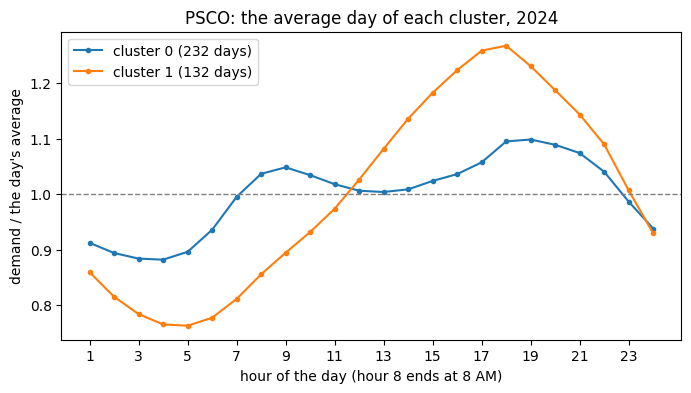

The figure's data, one line per cluster: demand / the day's average, hours 1 to 24
cluster 0: 0.91 0.89 0.88 0.88 0.90 0.94 1.00 1.04 1.05 1.03 1.02 1.01 1.00 1.01 1.02 1.04 1.06 1.10 1.10 1.09 1.07 1.04 0.99 0.94
cluster 1: 0.86 0.82 0.78 0.77 0.76 0.78 0.81 0.86 0.89 0.93 0.97 1.03 1.08 1.14 1.18 1.22 1.26 1.27 1.23 1.19 1.14 1.09 1.01 0.93


In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
hours = np.arange(1, 25)
for c in range(final_model.n_clusters):
    in_c = final_model.labels_ == c
    ax.plot(hours, shapes[in_2024][in_c].mean(axis=0), marker="o", markersize=3,
            label=f"cluster {c} ({in_c.sum()} days)")
ax.axhline(1.0, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("hour of the day (hour 8 ends at 8 AM)")
ax.set_ylabel("demand / the day's average")
ax.set_title(f"{REGION}: the average day of each cluster, 2024")
ax.set_xticks(hours[::2])
ax.legend()
plt.show()
# The figure's numbers, printed so the description can quote them.
print("The figure's data, one line per cluster: demand / the day's average, hours 1 to 24")
for c in range(final_model.n_clusters):
    line = shapes[in_2024][final_model.labels_ == c].mean(axis=0)
    print(f"cluster {c}:", " ".join(f"{v:.2f}" for v in line))

Cluster 0 starts close to its daily average in hour 1 (0.91), reaches a minimum of 0.88 in hours 3 and 4, and rises to a prolonged evening plateau peaking at 1.10 in hours 18 and 19. Cluster 1 has a much deeper overnight drop, bottoming out at 0.76 in hour 5, then rises sharply through the morning and afternoon to a peak of 1.27 in hour 18 (with 1.26 in hour 17). That looks like air conditioning load in the late afternoon, tapering off quickly at night.

### 3.5 Giving every day, 2024 and 2025, a type

Each day joins its nearest cluster center (`final_model.predict`). The type shares in the two years are similar, which suggests the 2024 types carry over to 2025.

In [12]:
types = final_model.predict(X)

# Calculate shares for 2024 and 2025
shares_2024 = pd.Series(types[in_2024]).value_counts(normalize=True).sort_index()
shares_2025 = pd.Series(types[in_2025]).value_counts(normalize=True).sort_index()

shares_df = pd.DataFrame({
    '2024 Share': shares_2024,
    '2025 Share': shares_2025
})
shares_df.index.name = 'Cluster'
display(shares_df)

,2024 Share,2025 Share
Cluster,,
0,0.637363,0.688705
1,0.362637,0.311295


In [13]:
type_names = ["Winter-Spring Evening-Peak Days", "Summer-Fall Late-Afternoon Days"]

## 4. Predicting tomorrow's day type (supervised learning)

Section 3 gave every day a type, but only after the day was over: its type comes from its own 24 hours. A battery deciding at midnight what to do tomorrow does not have those hours yet. So here I train a classifier, with the day types as labels, to predict tomorrow's type from what is known at midnight.

**The midnight rule:** a feature is allowed only if it is fully known before the target day begins. The month, the day of the week, and yesterday's 24 hours are. Today's own hours are not, because they are the answer. Breaking the rule is **data leakage**: the model would look excellent in training and fail when deployed, because the information would not exist at decision time.

`yesterday` holds, for every day, the previous row's 24-hour shape (the first day has none, so its row is zeros). `has_yesterday` is True where that previous row really is the day before, since a day dropped in 3.1 leaves a gap.

In [14]:
yesterday = np.vstack([np.zeros(24), shapes[:-1]])          # row i holds row i-1's shape
has_yesterday = np.r_[False, (dates[1:] - dates[:-1]).days == 1]
print("days with yesterday in the matrix:", has_yesterday.sum(), "of", len(has_yesterday))

days with yesterday in the matrix: 722 of 727


### Features and models

Features: 12 one-hot columns for the month, 7 for the day of the week, and 24 for yesterday's shape (43 in all). I fit on 2024 days and score on 2025 days, and compare against the majority-class baseline (always guessing 2024's most common type). I train logistic regression and a random forest; the better one's predictions for every day are kept for the battery agent.

In [15]:
month_features = np.eye(12)[dates.month - 1]
weekday_features = np.eye(7)[dates.dayofweek]
F = np.hstack([month_features, weekday_features, yesterday])

fit_rows = np.where(in_2024 & has_yesterday)[0]
score_rows = np.where(in_2025 & has_yesterday)[0]

print("Features used:")
print("- 12 columns for one-hot encoded month")
print("- 7 columns for one-hot encoded day of the week")
print("- 24 columns for yesterday's 24-hour hourly shape")
print("F shape:", F.shape)
print("fit_rows (2024):", len(fit_rows))
print("score_rows (2025):", len(score_rows))

Features used:
- 12 columns for one-hot encoded month
- 7 columns for one-hot encoded day of the week
- 24 columns for yesterday's 24-hour hourly shape
F shape: (727, 43)
fit_rows (2024): 361
score_rows (2025): 361


In [16]:
train_labels = types[fit_rows]
test_labels = types[score_rows]

# Most common type in 2024
majority_class = pd.Series(train_labels).value_counts().idxmax()
baseline_accuracy = (test_labels == majority_class).mean()
print(f"Majority-class baseline accuracy on 2025: {baseline_accuracy:.4f} (always guessing {majority_class})")

# Train and score Logistic Regression
from sklearn.linear_model import LogisticRegression
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=0))
lr.fit(F[fit_rows], train_labels)
lr_acc = lr.score(F[score_rows], test_labels)
print(f"Logistic Regression accuracy on 2025: {lr_acc:.4f}")

# Train and score Random Forest
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=100, random_state=0)
rf.fit(F[fit_rows], train_labels)
rf_acc = rf.score(F[score_rows], test_labels)
print(f"Random Forest Classifier accuracy on 2025: {rf_acc:.4f}")

# Save predictions of the better model for all days
best_model = rf if rf_acc >= lr_acc else lr
predicted_types = best_model.predict(F)

Majority-class baseline accuracy on 2025: 0.6870 (always guessing 0)
Logistic Regression accuracy on 2025: 0.9030
Random Forest Classifier accuracy on 2025: 0.8920


Logistic regression (90.30%) edged out the random forest (89.20%), and both vastly outperformed the majority-class baseline of 68.70%. So the ensemble did not earn its place over the simpler model in this run. The confusion table shows where the errors are:

In [17]:
print("Confusion Table for 2025 predictions:")
_ = confusion_table(types[score_rows], predicted_types[score_rows], type_names)

Confusion Table for 2025 predictions:
                                      pred Winter-Spring Evening-Peak Days  pred Summer-Fall Late-Afternoon Days
true Winter-Spring Evening-Peak Days                                   223                                    25
true Summer-Fall Late-Afternoon Days                                    10                                   103


## 5. The battery agent (reinforcement learning)

Now an agent learns, by trial and error, when the battery should charge and when it should give the energy back, with the day type as part of what it sees.

### 5.1 The environment and its floor

The battery is built from every day's relative load. Two policies set the bar on 2024's days: doing nothing (exactly 0) and the clock rule (charge from 1 to 5 AM, discharge from 5 to 9 PM, otherwise hold), whose score is the first number the agent has to beat.

In [18]:
signal = values / values.mean(axis=1, keepdims=True)   # relative load, one row per day
train_days = np.where(in_2024)[0]
test_days = np.where(in_2025)[0]
env = BatteryEnv(signal)
do_nothing = run_policy(env, train_days, lambda day, hour, charge: HOLD)
clock = run_policy(env, train_days, clock_rule)
print(f"{REGION}, 2024, mean daily score: do nothing {do_nothing.mean():.4f}, "
      f"clock rule {clock.mean():.4f}")

PSCO, 2024, mean daily score: do nothing 0.0000, clock rule 0.6738


### 5.2 Q-learning with the day type in the state

The agent uses tabular **Q-learning**. The Q-table holds one number, a **Q-value**, for every combination of day type, hour, charge level, and action: how good that move looks, counting every reward until the day ends. It is indexed `Q[day type, hour, charge, action]`. Each episode is one randomly drawn 2024 day. Each hour the agent picks an action (a random one with probability epsilon, otherwise the best-looking one), then nudges that Q-value toward the reward it got plus the best Q-value available next.

Settings:

* **Episodes:** 50,000 (100,000 adds almost nothing)
* **Learning rate (alpha):** 0.1
* **Discount (gamma):** 1.0, since the episode is one day
* **Epsilon:** starts at 1.0 and decays linearly to 0.01 across all 50,000 episodes

An agent that does not know the day type is the same code given a day type of 0 for every day.

In [19]:
def epsilon_at(episode, episodes):
    """Decay epsilon linearly from 1.0 to 0.01 across the training episodes."""
    return max(0.01, 1.0 - (1.0 - 0.01) * (episode / max(1, episodes)))

def choose_action(Q_state, epsilon, rng):
    """Epsilon-greedy action selection for three actions (0, 1, 2)."""
    if rng.random() < epsilon:
        return rng.integers(3)  # Three possible actions: 0, 1, 2
    else:
        return int(np.argmax(Q_state))

def q_update(Q, t, hour, charge, action, reward, next_hour, next_charge, alpha, gamma):
    """Bellman update equation for a state-action pair including day type t."""
    if next_hour == 24:
        target = reward
    else:
        target = reward + gamma * np.max(Q[t, next_hour, next_charge])
    Q[t, hour, charge, action] += alpha * (target - Q[t, hour, charge, action])

def train(env, days, day_type, n_types, episodes=50000, alpha=0.1, gamma=1.0, seed=0, eval_episodes=None, score=None):
    """Standard RL loop to train the battery agent over multiple episodes."""
    rng = np.random.default_rng(seed)
    # Q-table dimensions: day types, 24 hours, charge states (0 to capacity), 3 actions
    Q = np.zeros((n_types, 24, env.capacity + 1, 3))

    # Tracking learning progress
    progress_points = set(eval_episodes) if eval_episodes is not None else set()

    for ep in range(episodes):
        day = rng.choice(days)
        t = day_type[day]

        hour, charge = env.reset(day)
        done = False

        epsilon = epsilon_at(ep, episodes)

        while not done:
            action = choose_action(Q[t, hour, charge], epsilon, rng)
            (next_hour, next_charge), reward, done = env.step(action)

            q_update(Q, t, hour, charge, action, reward, next_hour, next_charge, alpha, gamma)

            hour, charge = next_hour, next_charge

        # Evaluate intermediate progress points
        if (ep + 1) in progress_points and score is not None:
            score(Q)

    return Q

### 5.3 Learning curve

The true-day-type agent is trained once, and its greedy policy (exploration off) is scored on 2025's days as a share of the oracle at five points along the way.

In [20]:
eval_steps = (2000, 5000, 10000, 20000, 50000)
progress_scores = []

def score_q_table(Q):
    # Defines a greedy policy based on the current Q-table
    greedy_policy = lambda day, hour, charge: int(np.argmax(Q[types[day], hour, charge]))
    score_share = share_of_oracle(env, test_days, greedy_policy)
    progress_scores.append(score_share)
    print(f"Completed training step... current test set share of oracle: {score_share:.4f}")

print("Starting Q-learning training and evaluating learning curve...")
Q_trained = train(
    env=env,
    days=train_days,
    day_type=types,
    n_types=K,
    episodes=50000,
    alpha=0.1,
    gamma=1.0,
    seed=0,
    eval_episodes=eval_steps,
    score=score_q_table
)

print("\nLearning curve summary on 2025 Test Days:")
for step, score in zip(eval_steps, progress_scores):
    print(f"Episodes: {step:>5} | Share of Oracle: {score:.4f}")

Starting Q-learning training and evaluating learning curve...
Completed training step... current test set share of oracle: 0.2104
Completed training step... current test set share of oracle: 0.5065
Completed training step... current test set share of oracle: 0.7665
Completed training step... current test set share of oracle: 0.8478
Completed training step... current test set share of oracle: 0.8610

Learning curve summary on 2025 Test Days:
Episodes:  2000 | Share of Oracle: 0.2104
Episodes:  5000 | Share of Oracle: 0.5065
Episodes: 10000 | Share of Oracle: 0.7665
Episodes: 20000 | Share of Oracle: 0.8478
Episodes: 50000 | Share of Oracle: 0.8610


The score climbs from 21.0% of the oracle after 2,000 episodes to 86.1% after 50,000, with most of the gain in the first 20,000.

### 5.4 Does the day type help?

Three agents, each trained with 3 seeds and scored greedy on 2025: one that does not know the day type, one that knows the true type, and one that trains on the true types but acts on the types the Section 4 classifier predicted at midnight (the realistic case). The table shows each agent's mean share of the oracle and its spread (lowest to highest seed).

In [21]:
seeds = [0, 1, 2]
n_episodes = 50000

scores_no_type = []
scores_true_type = []
scores_pred_type = []

# We will store the seed-0 Q-table from the true-type agent
Q_true = None

for seed in seeds:
    # 1. Agent that does not know the day type (represented as a single day type '0' for all days)
    no_type_array = np.zeros(len(types), dtype=int)
    Q_no = train(env, train_days, no_type_array, n_types=1, episodes=n_episodes, seed=seed)
    greedy_no = lambda day, hour, charge: int(np.argmax(Q_no[0, hour, charge]))
    scores_no_type.append(share_of_oracle(env, test_days, greedy_no))

    # 2. Agent that knows the true day type
    Q_tr = train(env, train_days, types, n_types=K, episodes=n_episodes, seed=seed)
    greedy_tr = lambda day, hour, charge: int(np.argmax(Q_tr[types[day], hour, charge]))
    scores_true_type.append(share_of_oracle(env, test_days, greedy_tr))

    if seed == 0:
        Q_true = Q_tr

    # 3. Agent that trains on true day types but acts on predicted types at midnight
    # We use Q_tr (trained on true types) but evaluation acts using predicted_types
    greedy_pr = lambda day, hour, charge: int(np.argmax(Q_tr[predicted_types[day], hour, charge]))
    scores_pred_type.append(share_of_oracle(env, test_days, greedy_pr))

print(f"{'Agent Type':<30} | {'Mean Share':<10} | {'Spread (Min - Max)':<20}")
print("-" * 70)
for name, scores in [
    ("No Day Type", scores_no_type),
    ("True Day Type", scores_true_type),
    ("Predicted Day Type", scores_pred_type)
]:
    mean_val = np.mean(scores)
    spread_val = f"{np.min(scores):.4f} to {np.max(scores):.4f}"
    print(f"{name:<30} | {mean_val:.4f}     | {spread_val:<20}")

Agent Type                     | Mean Share | Spread (Min - Max)  
----------------------------------------------------------------------
No Day Type                    | 0.7472     | 0.6851 to 0.8048    
True Day Type                  | 0.8303     | 0.8141 to 0.8610    
Predicted Day Type             | 0.8307     | 0.8155 to 0.8604    


### 5.5 Comparing against the simple rules

Everything on 2025's days as a share of the oracle: doing nothing, the clock rule, the **fitted rule** (charge in the 4 quietest hours and discharge in the 4 busiest hours of 2024's average day), and the mean of each agent.

In [22]:
# 1. Evaluate simple rule baselines on 2025 test days
share_do_nothing = share_of_oracle(env, test_days, lambda day, hour, charge: HOLD)
share_clock = share_of_oracle(env, test_days, clock_rule)

fitted_policy = make_fitted_rule(signal[train_days])
share_fitted = share_of_oracle(env, test_days, fitted_policy)

# 2. Extract means computed from our 4d simulation results
mean_no_type = np.mean(scores_no_type)
mean_true_type = np.mean(scores_true_type)
mean_pred_type = np.mean(scores_pred_type)

# 3. Present the comparative results in a clean table
results_table = pd.DataFrame({
    "Policy / Agent": [
        "Do Nothing (Floor)",
        "Clock Rule",
        "Fitted Rule",
        "RL Agent: No Day Type (Mean)",
        "RL Agent: True Day Type (Mean)",
        "RL Agent: Predicted Day Type (Mean)"
    ],
    "2025 Share of Oracle": [
        share_do_nothing,
        share_clock,
        share_fitted,
        mean_no_type,
        mean_true_type,
        mean_pred_type
    ]
})

display(results_table)

,Policy / Agent,2025 Share of Oracle
0,Do Nothing (Floor),0.000000
1,Clock Rule,0.804813
2,Fitted Rule,0.832904
3,RL Agent: No Day Type (Mean),0.747245
4,RL Agent: True Day Type (Mean),0.830266
5,RL Agent: Predicted Day Type (Mean),0.830712


* Knowing the day type is worth about **8.3 points** of the oracle: the true-type agent scored 83.03% and the predicted-type agent 83.07%, against 74.72% for the agent without a day type. Using the *predicted* types cost nothing, because the midnight classifier is right about 90% of the time.
* Both day-type agents beat the clock rule (80.48%), but they only **tied the fitted rule** (83.29%).

I expect the gain from the day type to hold in future years, because the two shapes reflect seasonal temperature cycles that recur annually. That expectation rests on only two years of data, though.

### 5.6 What the agent learned

The plan the true-type agent follows for each day type, one letter per hour: `C` charge a unit, `D` discharge a unit, `.` do nothing.

In [23]:
levels = []
for c in range(K):
    plan_levels = show_policy(env, Q_true, c, type_names[c])
    levels.append(plan_levels)

Winter-Spring Evening-Peak Days hours 1-24: .CCCC............DDDD...
Summer-Fall Late-Afternoon Days hours 1-24: ...CCCC........DDDD.....


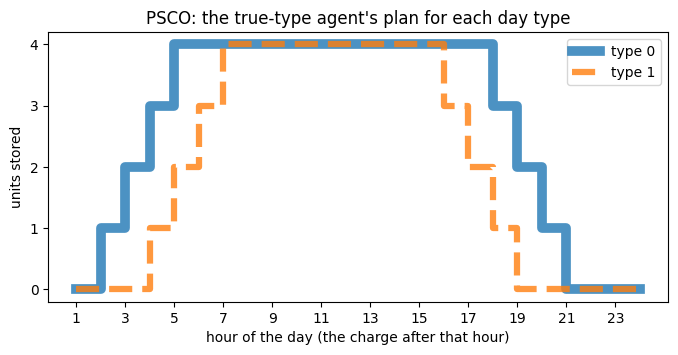

The figure's data, one line per day type: units stored after hours 1 to 24
type 0: 0 1 2 3 4 4 4 4 4 4 4 4 4 4 4 4 4 3 2 1 0 0 0 0
type 1: 0 0 0 1 2 3 4 4 4 4 4 4 4 4 4 3 2 1 0 0 0 0 0 0


In [24]:
fig, ax = plt.subplots(figsize=(8, 3.5))
# The first line is the thickest and the later ones thinner and on top, so two day
# types that share a plan still show side by side.
styles = [("-", 7), ("--", 4.5), (":", 3), ("-.", 1.8)]
for c, line in enumerate(levels):
    style, width = styles[c % len(styles)]
    ax.step(np.arange(1, 25), line, where="post", linestyle=style, linewidth=width,
            alpha=0.8, label=f"type {c}")
ax.set_xlabel("hour of the day (the charge after that hour)")
ax.set_ylabel("units stored")
ax.set_yticks(range(env.capacity + 1))
ax.set_ylim(-0.2, env.capacity + 0.2)
ax.set_title(f"{REGION}: the true-type agent's plan for each day type")
ax.set_xticks(np.arange(1, 25, 2))
ax.legend()
plt.show()
# The figure's numbers, printed so the description can quote them.
print("The figure's data, one line per day type: units stored after hours 1 to 24")
for c, line in enumerate(levels):
    print(f"type {c}:", " ".join(str(v) for v in line))

* **Winter-Spring Evening-Peak Days:** the battery charges in hours 2 to 5 (1 to 5 AM) until it holds 4 units, holds the full charge through the day, then discharges in hours 18 to 21 (5 to 9 PM), emptying by hour 21. This matches the cluster's evening plateau, which peaks in hour 19.
* **Summer-Fall Late-Afternoon Days:** charging starts later, in hours 4 to 7 (3 to 7 AM), reaching 4 units in hour 7. It holds the charge until hour 16, then discharges through hour 19 (3 to 7 PM) and is empty by hour 19. This aligns with the afternoon cooling load peaking in hour 18.

The agent worked out, with no schedule given to it, that the schedule should shift with the season, and it matches each cluster's peak.

## 6. Three kinds of learning on one grid

| | What it learned from | What told it whether it was right | What it produced on this grid | The number that judged it, and the baseline beside it | Where it went wrong or would mislead |
|---|---|---|---|---|---|
| **Unsupervised** (Section 3) | 24-hour demand shapes from 2024 | Distance from cluster centers (no labels) | Two stable day types: "Winter-Spring Evening-Peak" and "Summer-Fall Late-Afternoon" | Silhouette 0.4951 vs 0.3986 (highest no-cluster baseline) | Groups days purely by relative shape, ignoring the absolute size of the peaks |
| **Supervised** (Section 4) | Month, day of week, and yesterday's shape, all known by midnight | The day types from Section 3 as labels | A logistic regression that predicts tomorrow's day type | 90.30% accuracy vs 68.70% (majority-class baseline) | Can be misled by unusual weather transitions |
| **Reinforcement** (Section 5) | Hourly trial and error in the battery environment | Rewards: the cost of charging vs 90% of the value of discharging | A greedy charge/discharge plan for each day type | 83.07% of the oracle (predicted-type agent) vs 74.72% (no day type), 80.48% (clock rule), and 83.29% (fitted rule) | Assumes a fixed 10% round-trip loss on every step and ignores battery degradation |

### Cooperation of different learning types

Each kind of learning solved a piece of the problem that the other two could not:

1. **Unsupervised learning** discovered the structure (k = 2) and created the target classes. With no historical labels to copy, supervised learning could not do this, and reinforcement learning needs a structured state signal to optimize against. It handed 727 labeled days to the classifier.
2. **Supervised learning** handled the real-world timing constraint: predicting tomorrow's type at midnight (90.30% accuracy) to avoid leakage. Clustering cannot do this because it needs the full 24 hours of a day, and reinforcement learning does not predict the environment. It handed a predicted day type to the agent.
3. **Reinforcement learning** turned day types into sequential battery actions under a capacity limit (0 to 4 units) and a 10% round-trip loss, a multi-step control problem neither of the other two methods solves.

### How I knew each part was good without labels

In ordinary supervised work there is a ground-truth label to copy and accuracy is the judge. Here the clusters had no labels, so I had to define correctness myself: the silhouette had to beat a no-cluster baseline (0.4951 vs 0.3986), and the grouping had to be stable (ARI 1.0000 across 10 seeds). The agent was judged against a floor (do nothing, 0.00), a ceiling (the oracle with perfect foresight), and two simple rules.

### One honest failure

The reinforcement learning agent's 83.03% to 83.07% of the oracle looks impressive on its own, but a zero-learning rule does the same job. The fitted rule, which charges in the 4 quietest hours and discharges in the 4 busiest hours of 2024's average day, scored 83.29%. Reporting only the agent's success would suggest reinforcement learning is necessary to run this battery. On a grid as regular as PSCO's, it is not.

## 7. Summary and recommendation

To lower a city's peak-demand costs under Colorado's variable demand, I evaluated a virtual 4-unit battery on the PSCO grid. Three findings:

1. **The grid has two stable kinds of day:** Winter-Spring Evening-Peak Days and Summer-Fall Late-Afternoon Days (silhouette 0.4951, beating the no-cluster floor of 0.3986).
2. **Tomorrow's type is predictable at midnight:** 90.30% accuracy with logistic regression, against a majority-class floor of 68.70%.
3. **A learned agent works but does not beat a simple rule:** acting on the predicted types, the agent captured 83.07% of the oracle, well above doing nothing (0%) and the clock rule (80.48%), but level with the fitted rule (83.29%).

**Recommendation:** deploy the fitted rule first. It matches the k-means-based agent, is transparent, and has no computational overhead. The one case where learning looked worthwhile is the bonus experiment below: an agent trained on Ward-drawn day types reached 86.00% of the oracle, about 2.7 points above the fitted rule. That is worth following up with more years of data before committing to the added complexity.

This analysis makes no claim about emissions.

## 8. Limitations and next steps

In priority order:

1. **The environment is too simple (reinforcement-learning gap).** It assumes a fixed 10% round-trip loss on every cycle, regardless of battery age, temperature, or state of health, and real batteries degrade with rapid cycling. Next, add a degradation cost to the reward to discourage excessive cycling.
2. **Clustering ignores load magnitude (clustering gap).** Days are grouped strictly by relative shape, which hides level information such as peak megawatts. A mild 65°F summer day and a 100°F heatwave day can share a shape while differing enormously in grid stress. Next, add peak load level as a second state feature.
3. **Relative load is a stand-in for price (environment gap).** Real electricity prices depend on many factors that are hard to simulate, such as extreme weather. And if many batteries dispatch at the same hour, they collectively flatten the peak. Next, test the controller in a dynamic simulation with real price feeds.
4. **Two years is a short history.** Types, classifier, and agent are all fit on 2024 and judged on a single year, 2025, with 3 training seeds per agent. More years would show whether the 83% figures hold.

## Appendix: a second view of the day types

Do two other ways of clustering find the same day types, and does the battery agent care which method drew the boundaries?

### A.1 Ward hierarchical clustering

Agglomerative clustering with Ward's linkage (the merge that raises the total squared distance least), with the same k = 2 on 2024. I compare it with k-means by ARI.

In [25]:
from sklearn.cluster import AgglomerativeClustering

ac = AgglomerativeClustering(n_clusters=K, linkage='ward')
ward_labels = ac.fit_predict(X_train)

# Print cluster sizes
for cluster_id in range(K):
    size = np.sum(ward_labels == cluster_id)
    print(f"Cluster {cluster_id} size: {size}")

# Calculate and print ARI against k-means
ari = adjusted_rand_score(final_model.labels_, ward_labels)
print(f"ARI against k-means: {ari:.4f}")

Cluster 0 size: 146
Cluster 1 size: 218
ARI against k-means: 0.8513


Agglomerative clustering has no `predict`, so a day gets its Ward type by computing the distance from its 24-hour shape to each Ward cluster's average day (fit on 2024) and joining the nearest.

In [26]:
centroids = np.array([X_train[ward_labels == i].mean(axis=0) for i in range(K)])
ward_types = np.array([np.argmin(np.linalg.norm(centroids - row, axis=1)) for row in X])
print("Ward types assigned for all days. Unique counts:", np.bincount(ward_types))

Ward types assigned for all days. Unique counts: [261 466]


### A.2 Does the agent care?

The same agent is trained on the Ward day types with 3 seeds and scored greedy on 2025, beside the k-means true-type agent.

In [27]:
scores_ward_type = []
for seed in seeds:
    Q_ward = train(env, train_days, ward_types, n_types=K, episodes=n_episodes, seed=seed)
    greedy_ward = lambda day, hour, charge: int(np.argmax(Q_ward[ward_types[day], hour, charge]))
    scores_ward_type.append(share_of_oracle(env, test_days, greedy_ward))

mean_ward = np.mean(scores_ward_type)
spread_ward = f"{np.min(scores_ward_type):.4f} to {np.max(scores_ward_type):.4f}"

mean_km = np.mean(scores_true_type)
spread_km = f"{np.min(scores_true_type):.4f} to {np.max(scores_true_type):.4f}"

print(f"{'Method':<15} | {'Mean Share':<10} | {'Spread'}")
print("-" * 45)
print(f"{'K-Means True':<15} | {mean_km:.4f}     | {spread_km}")
print(f"{'Ward True':<15} | {mean_ward:.4f}     | {spread_ward}")

Method          | Mean Share | Spread
---------------------------------------------
K-Means True    | 0.8303     | 0.8141 to 0.8610
Ward True       | 0.8600     | 0.8597 to 0.8604


The agent did care. The Ward-type agent scored a mean of 0.8600 of the oracle (spread 0.8597 to 0.8604), about 3 points above the k-means true-type agent's 0.8303, and with a much narrower spread. The two groupings agree on most days (ARI 0.8513) but draw the boundary a little differently, and that was enough to matter. It is also the only agent here that beats the fitted rule (0.8329), which is why the recommendation above is hedged rather than a flat "never use RL".

### A.3 DBSCAN

DBSCAN grows clusters from crowded points and labels isolated points as noise (-1). Its result depends on `eps`, how close two days must be to count as neighbors. I try three values with `min_samples=5`, and list the noise days for the middle one.

In [28]:
eps_values = [0.05, 0.12, 0.25]

for eps in eps_values:
    db = DBSCAN(eps=eps, min_samples=5).fit(X_train)
    labels = db.labels_
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = np.sum(labels == -1)
    print(f"eps: {eps:.2f} | Clusters: {n_clusters} | Noise Days: {n_noise} of {len(X_train)}")

    # For the in-between value, list the noise days by date
    if eps == 0.12:
        noise_indices = np.where(labels == -1)[0]
        noise_dates = train_dates[noise_indices]
        print("\nNoise days for eps = 0.12:")
        for d in noise_dates:
            print(d.strftime('%Y-%m-%d'))

eps: 0.05 | Clusters: 0 | Noise Days: 364 of 364
eps: 0.12 | Clusters: 6 | Noise Days: 261 of 364

Noise days for eps = 0.12:
2024-01-01
2024-01-03
2024-01-04
2024-01-12
2024-01-13
2024-01-15
2024-01-17
2024-01-21
2024-01-29
2024-02-01
2024-02-02
2024-02-03
2024-02-06
2024-02-07
2024-02-08
2024-02-10
2024-02-11
2024-02-15
2024-02-20
2024-02-23
2024-02-24
2024-02-25
2024-02-26
2024-02-27
2024-02-29
2024-03-01
2024-03-03
2024-03-06
2024-03-09
2024-03-11
2024-03-12
2024-03-13
2024-03-16
2024-03-19
2024-03-20
2024-03-21
2024-03-23
2024-03-24
2024-03-25
2024-03-26
2024-03-27
2024-03-29
2024-03-31
2024-04-01
2024-04-02
2024-04-03
2024-04-05
2024-04-06
2024-04-07
2024-04-08
2024-04-09
2024-04-10
2024-04-13
2024-04-14
2024-04-15
2024-04-16
2024-04-17
2024-04-19
2024-04-20
2024-04-23
2024-04-25
2024-04-26
2024-04-27
2024-04-28
2024-05-01
2024-05-02
2024-05-03
2024-05-04
2024-05-05
2024-05-07
2024-05-08
2024-05-09
2024-05-10
2024-05-11
2024-05-12
2024-05-13
2024-05-14
2024-05-16
2024-05-17
2024-

At `eps = 0.05` every day is noise, and at `eps = 0.25` almost every day merges into a single cluster (1 cluster, 3 noise days). In between, at `eps = 0.12`, DBSCAN finds 6 small clusters but calls 261 of 364 days noise. So this region's days do not form separate, dense crowds; they form a continuous spread of shapes, which fits the modest silhouette at k = 2. The noise list at `eps = 0.12` does include holidays such as 2024-01-01, 2024-05-27 (Memorial Day), 2024-07-04, 2024-09-02 (Labor Day), 2024-11-28 (Thanksgiving), and 2024-12-25, which is plausible since holidays have unusual demand, but with 72% of days labeled noise, that is weak evidence that holidays are special.